In [1]:
import warnings
import os
warnings.simplefilter(action='ignore')
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
#parameters

### USER EDIT start
esm_file='/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PI-control/cm3-datastore/cm3-datastore.json'
dpi=300

# papermill settings. *No need to modify these if running interactively.*
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory
nbname = None                          # notebook name


In [3]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PI-control/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/"
nbname = "global-time-series.ipynb"


In [4]:
import os  # always: the old parameters cell imported it, and notebooks use os.* (TOA_CRE does)
if not papermill:
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter

import matplotlib as mpl
%matplotlib inline
mpl.rcParams['figure.dpi'] = dpi

mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)


In [5]:
import xarray as xr
import cf_xarray as cfxr
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import numpy as np
import dask.array as da
from itables import show
import h5py

In [6]:
client = Client(threads_per_worker=1, n_workers=4)
# client

In [7]:
#datastore_path = "/g/data/ol01/access-om3-output/access-om3-025/MC_25km_jra_ryf-1.0-beta/experiment_datastore.json"
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

In [8]:
def available_variables(datastore):
    """Return a pandas dataframe summarising the variables in a datastore"""
    variable_columns = [col for col in datastore.df.columns if "variable" in col]
    return (
        datastore.df[variable_columns]
        .explode(variable_columns)
        .drop_duplicates()
        .set_index("variable")
        .sort_index()
    )

In [9]:
datastore_filtered = datastore.search(realm="ocean")

for col in COLUMNS_WITH_ITERABLES:
    datastore_filtered.df[col] = datastore_filtered.df[col].astype("object").map(lambda x: list(map(str, x)))

df = available_variables(datastore_filtered)
show(df)

Loading ITables v2.8.1 from the internet... (need help?)


# Load ocean and atmosphere areas

In [10]:
wet = datastore.search(variable="wet")
wet.df.drop_duplicates(subset='filename', inplace=True)
wet = wet.to_dask().compute()

areacello = datastore.search(variable="areacello")
areacello.df.drop_duplicates(subset='filename', inplace=True)
areacello = areacello.to_dask().compute()

areacello = (areacello.areacello * (wet.wet == 1.0))

In [11]:
EARTH_RADIUS = 6371229.0
nlon, nlat = 192, 144
dx = 360 / nlon
dy = 180 / nlat

element_lat = (np.arange(nlat) + 0.5) * dy  - 90
element_lat = element_lat[:, None] * np.ones(nlon)[None, :]
element_lon = (np.arange(nlon) + 0.5) * dx

pi_over_180 = np.pi / 180
element_areas = dx * pi_over_180 * (
  np.sin((element_lat + 0.5 * dy) * pi_over_180) - np.sin((element_lat - 0.5 * dy) * pi_over_180)
)

areacella = element_areas * EARTH_RADIUS**2
areacella = xr.DataArray(areacella, coords=dict(lat=element_lat[:, 0], lon=element_lon), dims=('lat', 'lon'))

total_ocn_fraction = areacello.sum().data / areacella.sum().data

# Ocean time series

## Ocean heatflux

## Load CM3 data

In [12]:
cm3_ocean_heatflux = datastore.search(variable="net_heat_coupler", frequency="1mon").to_dask(
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        decode_timedelta=True
    )
).net_heat_coupler

In [13]:
# area weighted average of ocean heatflux
# average over entire earth for comparison with TOA
cm3_avg_ocean_heatflux = cm3_ocean_heatflux.weighted(areacello.fillna(0)).mean(dim=('yh', 'xh')).compute() * total_ocn_fraction

In [14]:
nyears = len(cm3_avg_ocean_heatflux.time) // 12

### Load CM2 data

In [15]:
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

In [16]:
# cz861

In [17]:
def load_cm2_data(var_name, year_start, year_end):

    da_list = []

    for year in range(year_start, year_end):
        for month in [1, 7]:
            
            fn = f'ocean-2d-{var_name}-1-monthly-mean-ym_{str(year).zfill(4)}_0{month}.nc'
            fp = f'/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/{fn}'
            da_list.append(
                xr.open_dataset(fp, drop_variables=["average_T1", "average_T2"], chunks="auto", decode_times=time_coder, decode_timedelta=False)[var_name]
            )

    return xr.concat(da_list, dim='time')


cm2_heatflux = load_cm2_data('sfc_hflux_coupler', 1, nyears+1).rename(yt_ocean="yh", xt_ocean="xh")

In [18]:
fp = f'/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-2d-area_t.nc'
cm2_area = xr.open_dataset(fp, decode_times=time_coder).area_t.data
cm2_area = xr.DataArray(cm2_area, coords=dict(yh=cm2_heatflux.yh, xh=cm2_heatflux.xh), dims=('yh', 'xh'))

In [19]:
cm2_avg_ocean_heatflux = cm2_heatflux.weighted(cm2_area.fillna(0)).mean(dim=('yh', 'xh')).compute() * total_ocn_fraction

### Plot

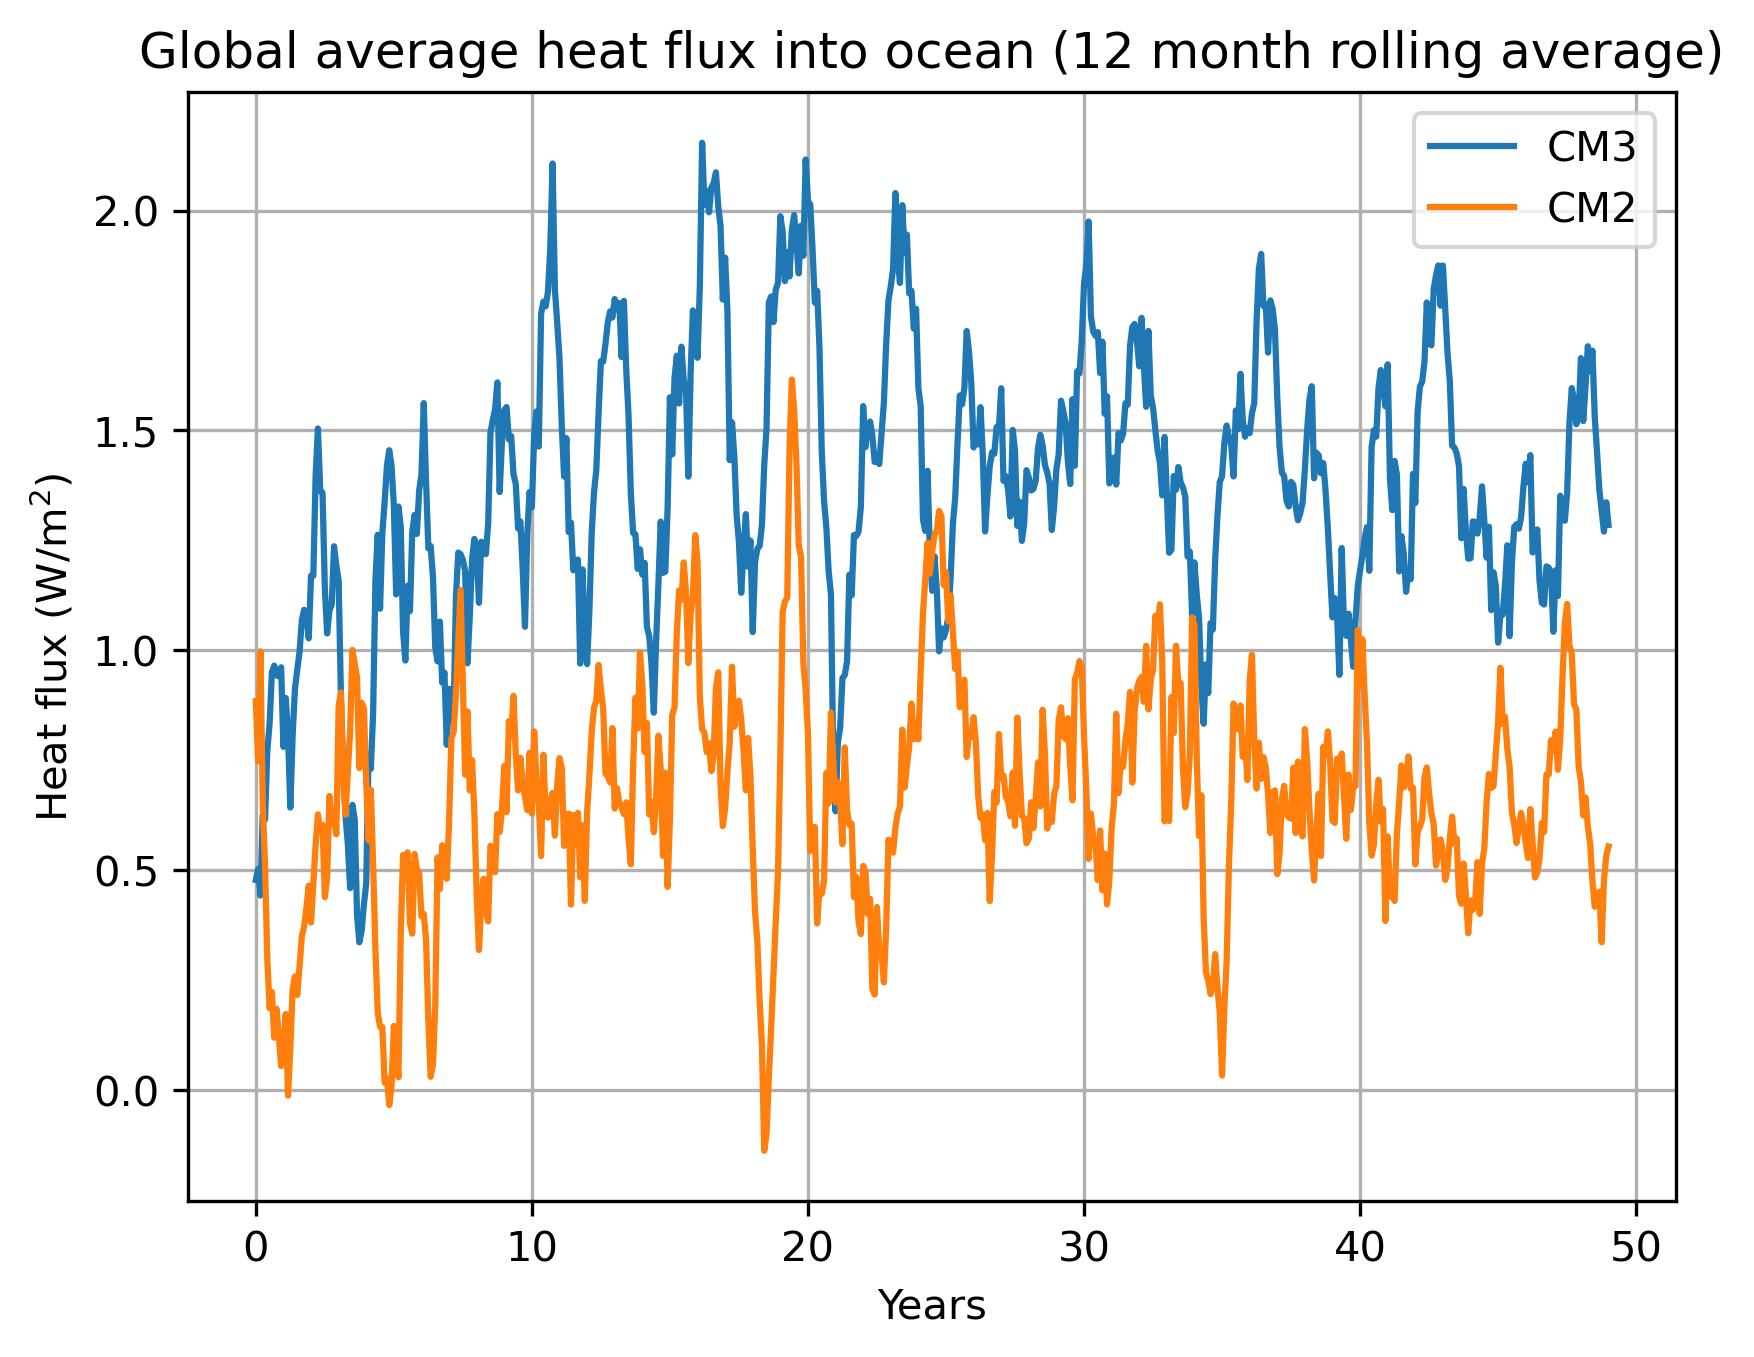

In [20]:
N = 12
rolling_avg = np.convolve(cm3_avg_ocean_heatflux, np.ones(N) / N, mode='valid')
plt.plot(np.arange(len(rolling_avg)) / 12, rolling_avg, label="CM3")

rolling_avg = np.convolve(cm2_avg_ocean_heatflux, np.ones(N) / N, mode='valid')
plt.plot(np.arange(len(rolling_avg)) / 12, rolling_avg, label="CM2")

plt.title('Global average heat flux into ocean (12 month rolling average)')
plt.ylabel('Heat flux (W/m$^2$)')
plt.xlabel('Years')
plt.legend()
plt.grid()

## SST

In [21]:
cm3_avg_sst = datastore.search(variable="tosga", frequency="1day").to_dask(
    xarray_open_kwargs = dict(
        decode_timedelta=True
    )
).tosga.compute()

In [22]:
year_start = 1
year_end = nyears+1
da_list = []

for year in range(year_start, year_end):
    for month in [1, 7]:
        
        fn = f'ocean-scalar-1-daily-ym_{str(year).zfill(4)}_0{month}.nc'
        da_list.append(xr.open_dataset(f'/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/{fn}', decode_times=time_coder)['temp_surface_ave'])

cm2_avg_sst = xr.concat(da_list, dim='time').data[:, 0]

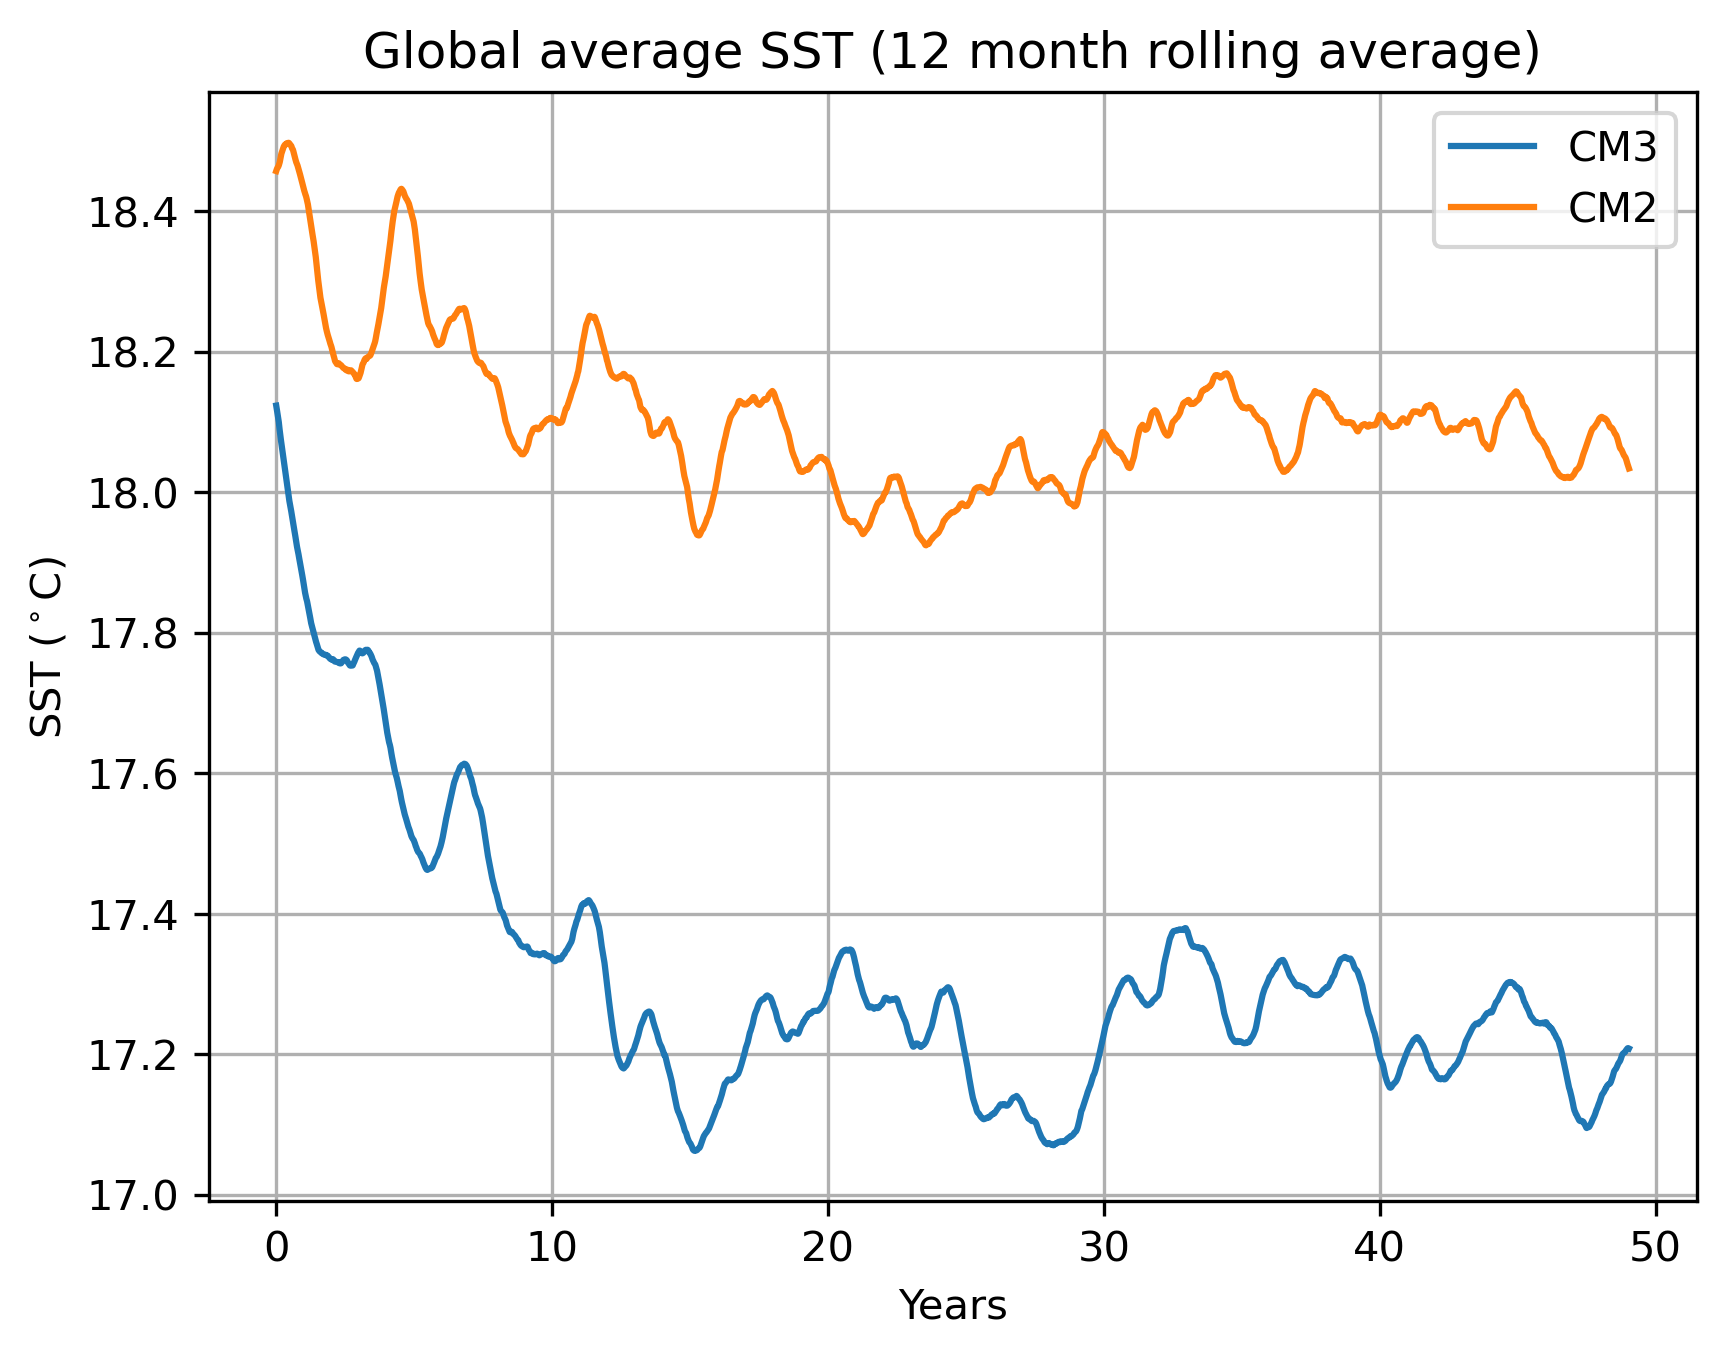

In [23]:
N = 365
avg_flx = np.convolve(cm3_avg_sst.data.ravel(), np.ones(N) / N, mode='valid')
plt.plot(np.arange(len(avg_flx)) / N, avg_flx, label='CM3')

avg_flx = np.convolve(cm2_avg_sst, np.ones(N) / N, mode='valid')
plt.plot(np.arange(len(avg_flx)) / N, avg_flx, label='CM2')

plt.title('Global average SST (12 month rolling average)')

plt.xlabel('Years')
plt.ylabel('SST ($^\circ$C)')
plt.legend()
plt.grid()

# Ice time series

## Ice area

### Load CM3 data

In [24]:
ice_fps = sorted(datastore.search(variable="aice_m", frequency="1mon").df.path.values)
ice_ds_list = [h5py.File(fp, "r") for fp in ice_fps]

In [25]:
%%time
cm3_ice_fraction = xr.DataArray(da.concatenate([da.from_array(ds["/aice_m"]) for ds in ice_ds_list]), dims=('time', 'nj', 'ni'))

CPU times: user 1.4 s, sys: 1.4 s, total: 2.8 s
Wall time: 5.29 s


In [26]:
cm3_sh_mask = areacello.data.copy()
cm3_sh_mask[cm3_sh_mask.data.shape[0]//2:] = 0
cm3_sh_mask = xr.DataArray(cm3_sh_mask, dims=('nj', 'ni')).fillna(0)

cm3_nh_mask = areacello.data.copy()
cm3_nh_mask[:cm3_nh_mask.data.shape[0]//2] = 0
cm3_nh_mask = xr.DataArray(cm3_nh_mask, dims=('nj', 'ni')).fillna(0)

In [27]:
%%time
cm3_nh_ice_area = cm3_ice_fraction.weighted(cm3_nh_mask).sum(dim=('nj', 'ni')).compute()
cm3_sh_ice_area = cm3_ice_fraction.weighted(cm3_sh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 11.8 s, sys: 4.43 s, total: 16.3 s
Wall time: 29.8 s


### Load CM2 data

In [28]:
cm2_sh_mask = cm2_area.data.copy()
cm2_sh_mask[cm2_sh_mask.data.shape[0]//2:] = 0
cm2_sh_mask = xr.DataArray(cm2_sh_mask, dims=('nj', 'ni')).fillna(0)

cm2_nh_mask = cm2_area.data.copy()
cm2_nh_mask[:cm2_nh_mask.data.shape[0]//2] = 0
cm2_nh_mask = xr.DataArray(cm2_nh_mask, dims=('nj', 'ni')).fillna(0)

In [29]:
year = month = 1
fn = f'iceh_m.{str(year).zfill(4)}-{str(month).zfill(2)}.nc'
fp = f'/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ice/{fn}'

all_vars = xr.open_dataset(fp).data_vars.keys()

keep_vars = ["aice", "vicen"]
drop_vars = [var for var in all_vars if not var in keep_vars]

In [30]:
%%time
cm2_cice_ds_list = []
year_start = 1
year_end = nyears+1
for year in range(year_start, year_end+1):
    for month in range(1, 13):
        fn = f'iceh_m.{str(year).zfill(4)}-{str(month).zfill(2)}.nc'
        fp = f'/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ice/{fn}'
        cm2_cice_ds_list.append(xr.open_dataset(fp, chunks=dict(time=1, nc=1, nj=-1, ni=-1)))

CPU times: user 2min 44s, sys: 56.9 s, total: 3min 41s
Wall time: 3min 52s


In [31]:
cm2_aice = xr.DataArray(da.concatenate([ds.aice.data for ds in cm2_cice_ds_list]), dims=('time', 'nj', 'ni'))

In [32]:
%%time
cm2_nh_ice_area = cm2_aice.weighted(cm2_nh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 10 s, sys: 4.78 s, total: 14.8 s
Wall time: 38.4 s


In [33]:
%%time
cm2_sh_ice_area = cm2_aice.weighted(cm2_sh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 6.91 s, sys: 2.86 s, total: 9.77 s
Wall time: 17.7 s


### Plot

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/global-time-series_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/global-time-series.md


Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/global-time-series.md successfully.


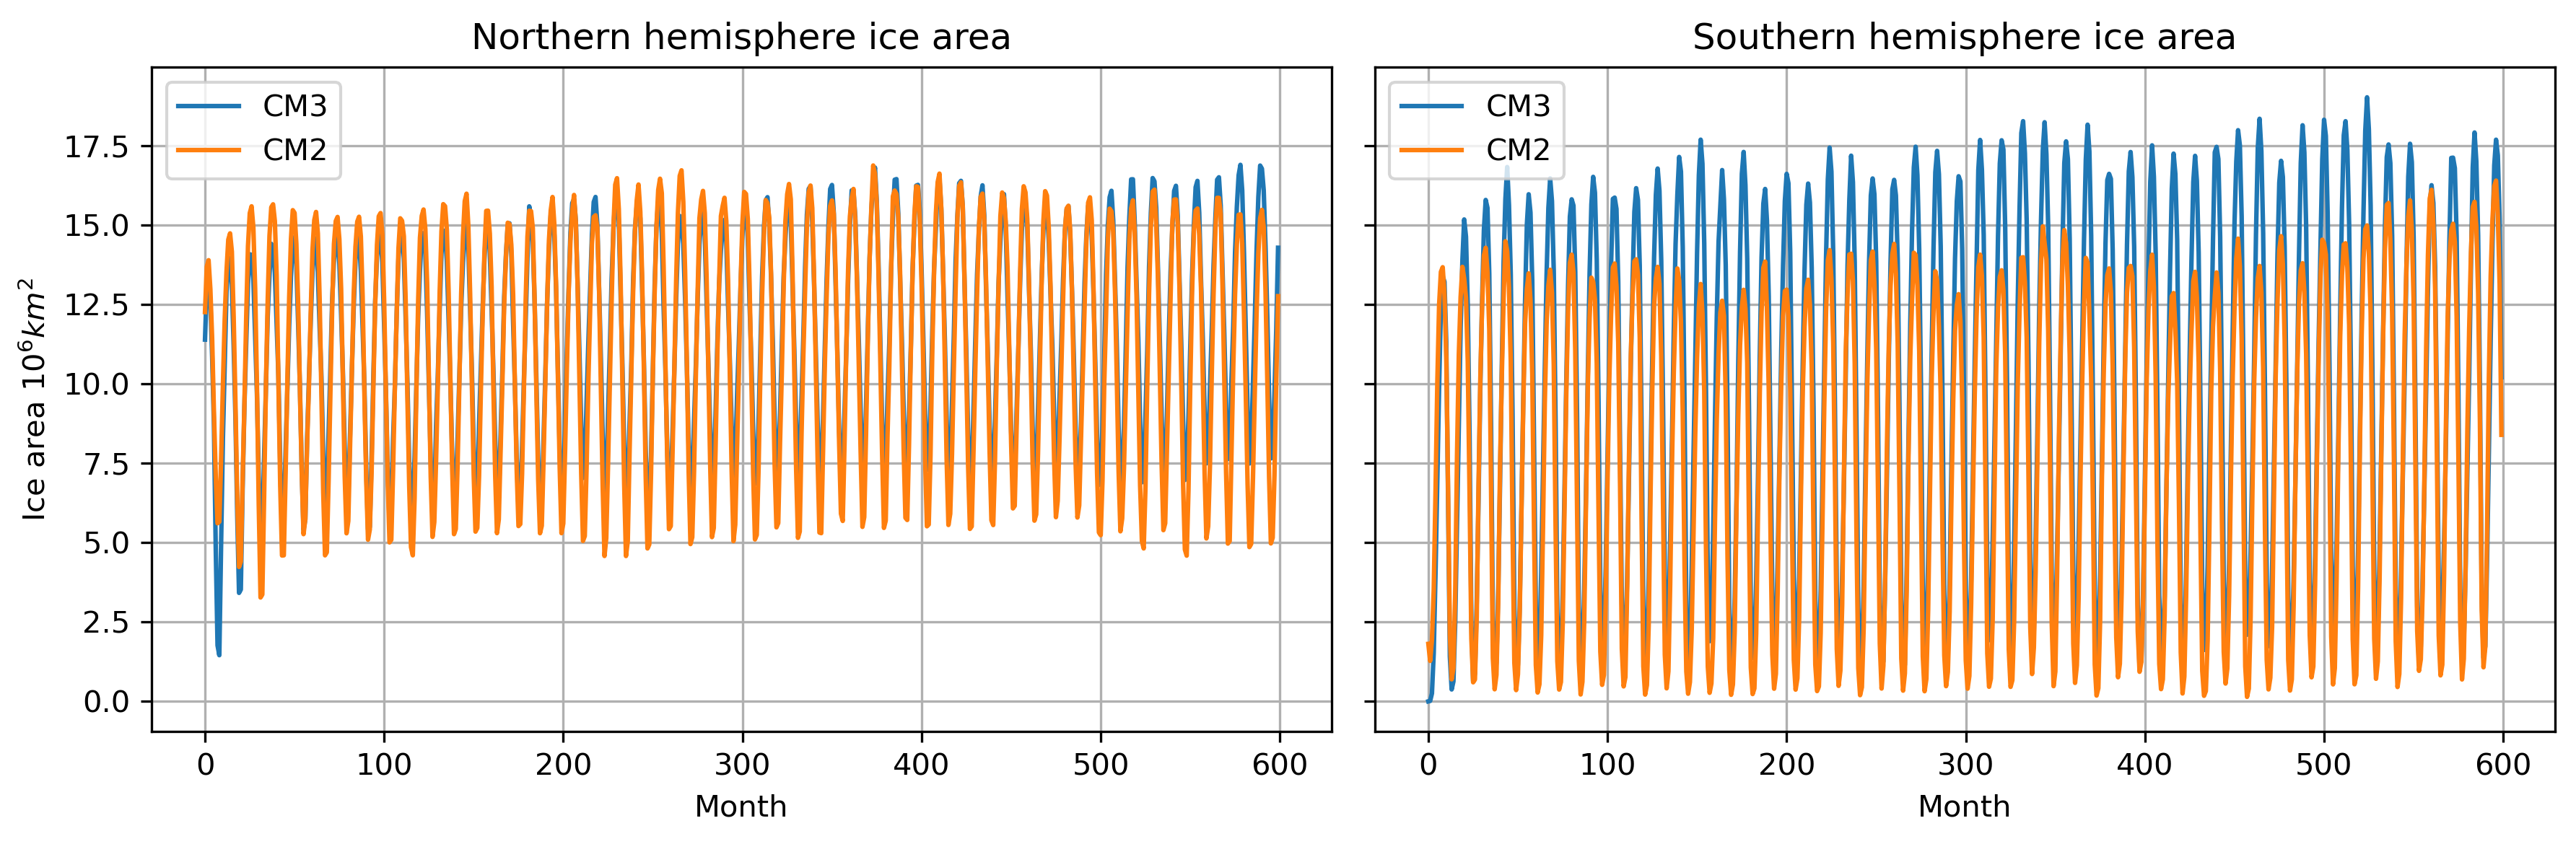

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.plot(cm3_nh_ice_area / 1e12, label='CM3')
ax1.plot(cm2_nh_ice_area[:len(cm3_nh_ice_area)] / 1e12, label='CM2')
ax2.plot(cm3_sh_ice_area / 1e12, label='CM3')
ax2.plot(cm2_sh_ice_area[:len(cm3_nh_ice_area)] / 1e12, label='CM2')

ax1.set_title('Northern hemisphere ice area')
ax1.set_ylabel('Ice area $10^6 km^2$')
ax1.set_xlabel('Month')
ax1.legend()

ax2.set_title('Southern hemisphere ice area')
ax2.set_xlabel('Month')
ax2.legend()
plt.tight_layout()
ax1.grid(True)
ax2.grid(True)
mkmd.savefig(fig, "Northern hemisphere ice area", "Time series of total sea-ice area in both hemispheres.", dpi=dpi)


## Ice volume

### Load CM3 data

In [35]:
%%time
cm3_ice_thickness = xr.DataArray(da.concatenate([da.from_array(ds["/hi_m"]) for ds in ice_ds_list]), dims=('time', 'nj', 'ni'))

CPU times: user 710 ms, sys: 228 ms, total: 938 ms
Wall time: 1.01 s


In [36]:
%%time
cm3_nh_ice_vol = cm3_ice_thickness.weighted(cm3_nh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 6.81 s, sys: 1.9 s, total: 8.71 s
Wall time: 12.6 s


In [37]:
%%time
cm3_sh_ice_vol = cm3_ice_thickness.weighted(cm3_sh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 4.99 s, sys: 1.75 s, total: 6.74 s
Wall time: 10.3 s


### Load CM2 data

In [38]:
cm2_ice_hickness = xr.DataArray(da.concatenate([ds.hi.data for ds in cm2_cice_ds_list]), dims=('time', 'nj', 'ni'))

In [39]:
%%time
cm2_nh_ice_vol = cm2_ice_hickness.weighted(cm2_nh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 9.83 s, sys: 4.59 s, total: 14.4 s
Wall time: 36.9 s


In [40]:
%%time
cm2_sh_ice_vol = cm2_ice_hickness.weighted(cm2_sh_mask).sum(dim=('nj', 'ni')).compute()

CPU times: user 6.58 s, sys: 2.86 s, total: 9.43 s
Wall time: 18 s


### Plot

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/global-time-series_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/global-time-series.md
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/global-time-series.md successfully.


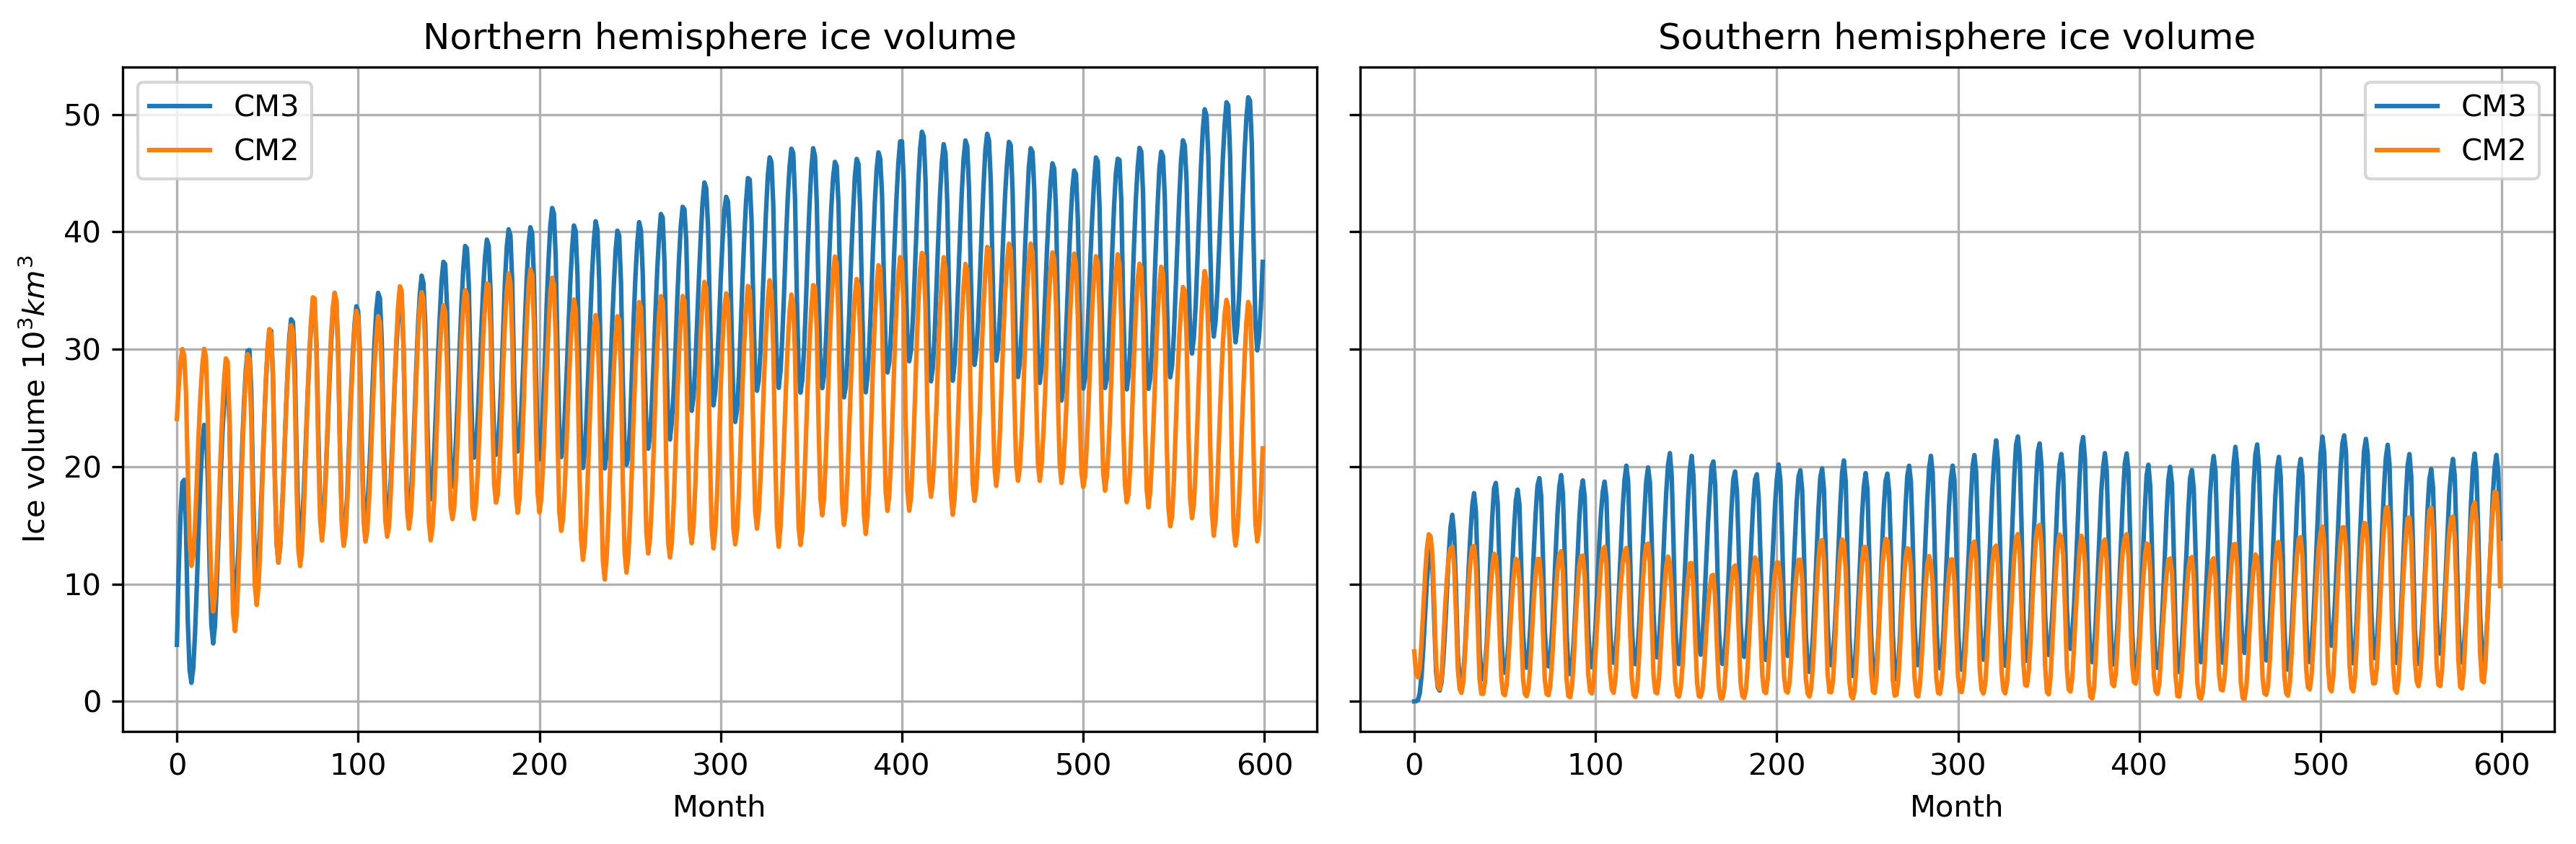

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.plot(cm3_nh_ice_vol / 1e12, label='CM3')
ax1.plot(cm2_nh_ice_vol[:len(cm3_nh_ice_vol)] / 1e12, label='CM2')
ax2.plot(cm3_sh_ice_vol / 1e12, label='CM3')
ax2.plot(cm2_sh_ice_vol[:len(cm3_nh_ice_vol)] / 1e12, label='CM2')

ax1.set_title('Northern hemisphere ice volume')
ax1.set_ylabel('Ice volume $10^3 km^3$')
ax1.set_xlabel('Month')
ax1.legend()

ax2.set_title('Southern hemisphere ice volume')
ax1.set_ylabel('Ice volume $10^3 km^3$')
ax2.set_xlabel('Month')
ax2.legend()
plt.tight_layout()
ax1.grid(True)
ax2.grid(True)
mkmd.savefig(fig, "Northern hemisphere ice volume", "Time series of total sea-ice volume in each hemisphere.", dpi=dpi)


# Atmosphere time series

## Load UM data manually

Loading the UM data using the datastore can be slow, so we load the data manually instead.

In [42]:
atm_fps = datastore.search(variable="fld_s01i208", frequency="1mon").df.sort_values(by='start_date').path.values
atm_ds_list = [h5py.File(fp, "r") for fp in atm_fps]

In [43]:
%%time
sw_out = xr.DataArray(da.concatenate([da.from_array(ds["/fld_s01i208"]) for ds in atm_ds_list]), dims=('time', 'lat', 'lon'))
lw_out = xr.DataArray(da.concatenate([da.from_array(ds["/fld_s02i205"]) for ds in atm_ds_list]), dims=('time', 'lat', 'lon'))
sw_in = xr.DataArray(da.concatenate([da.from_array(ds["/fld_s01i207"]) for ds in atm_ds_list]), dims=('time', 'lat', 'lon'))

CPU times: user 3.9 s, sys: 10.2 s, total: 14.1 s
Wall time: 35.3 s


In [44]:
toa = sw_in - sw_out - lw_out

In [45]:
%%time
avg_toa = toa.weighted(areacella).mean(dim=('lat', 'lon')).compute()

CPU times: user 12.4 s, sys: 4 s, total: 16.4 s
Wall time: 24 s


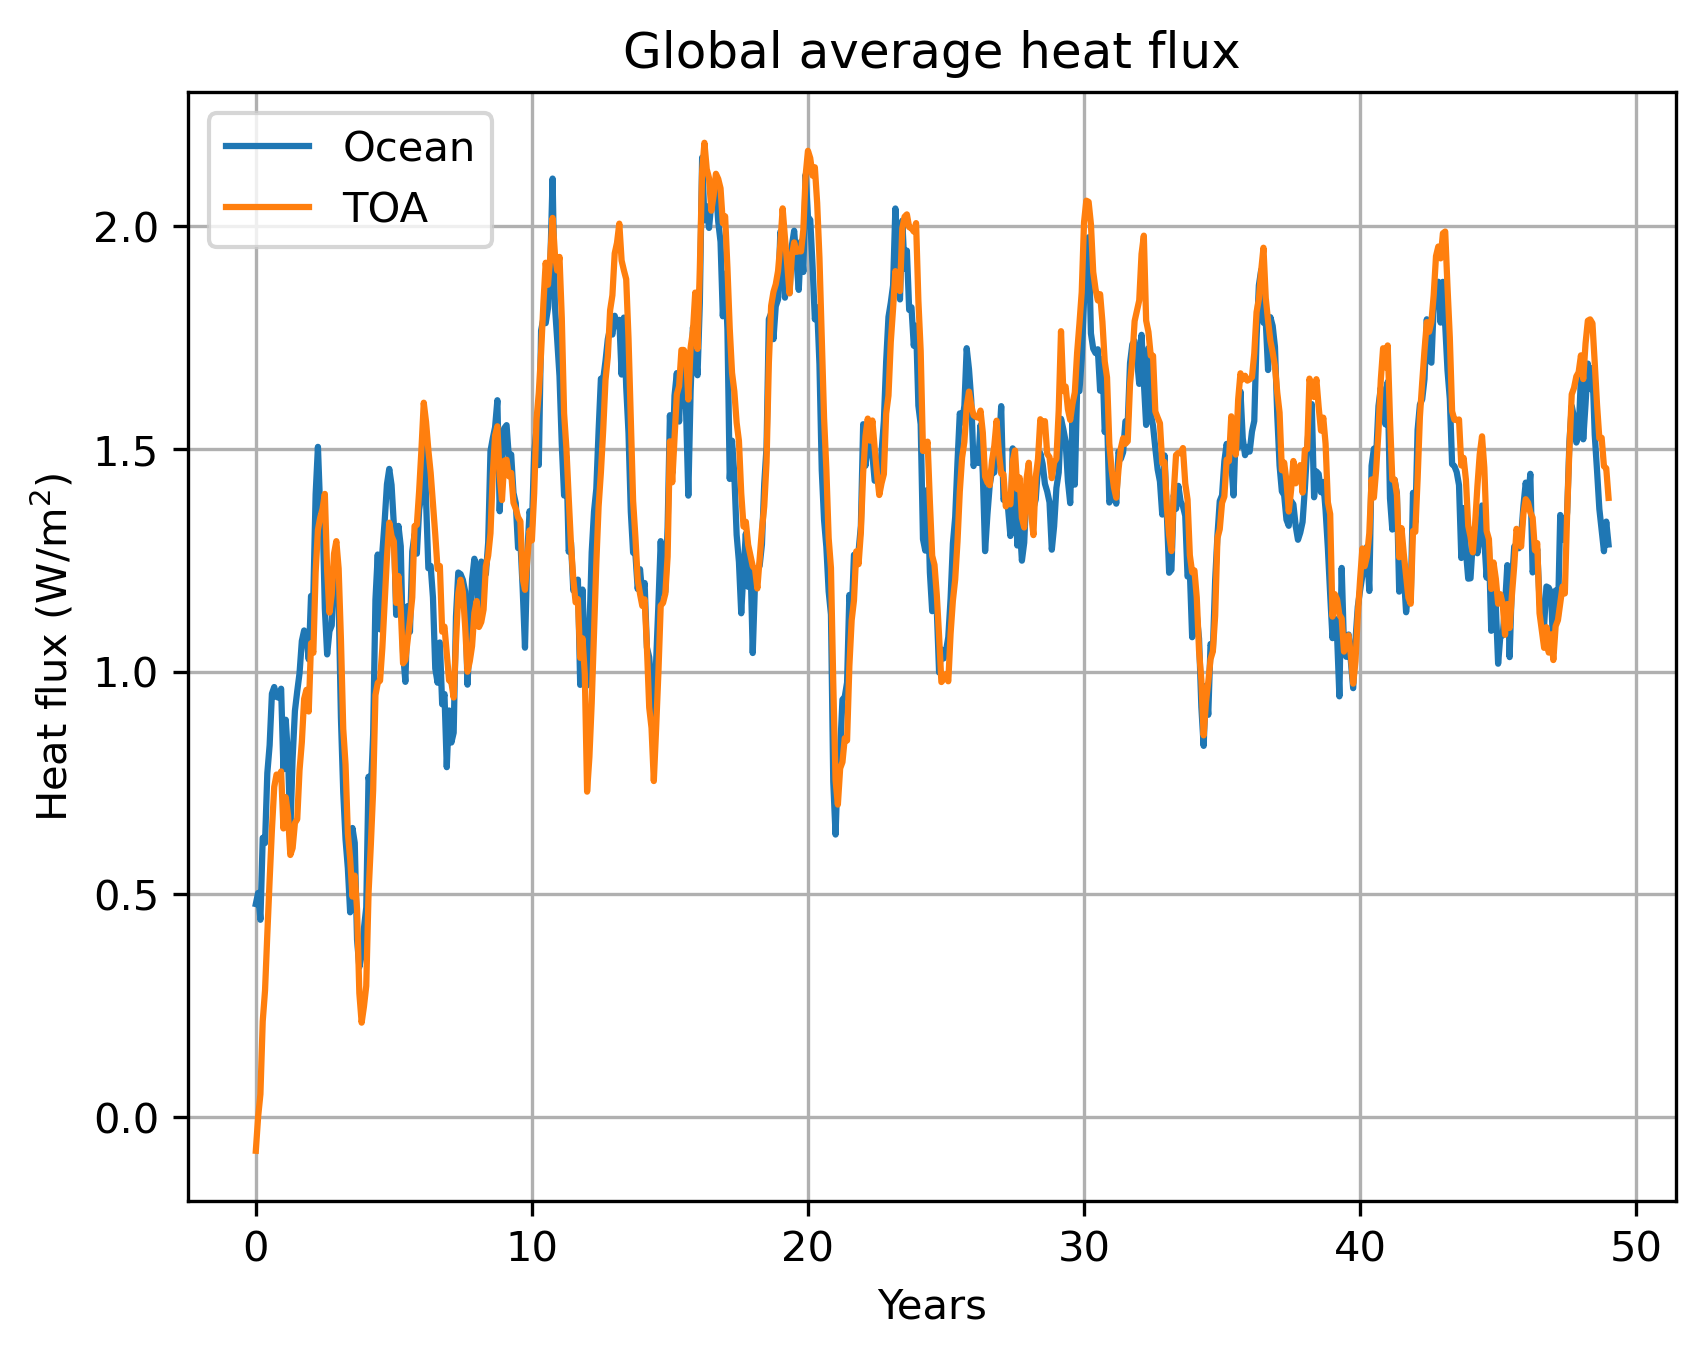

In [46]:
N = 12

rolling_avg = np.convolve(cm3_avg_ocean_heatflux, np.ones(N) / N, mode='valid')
plt.plot(np.arange(len(rolling_avg)) / 12, rolling_avg, label='Ocean')

rolling_avg = np.convolve(avg_toa, np.ones(N) / N, mode='valid')
plt.plot(np.arange(len(rolling_avg)) / 12, rolling_avg, label='TOA')

plt.title('Global average heat flux')

plt.ylabel('Heat flux (W/m$^2$)')
plt.xlabel('Years')
plt.legend()
plt.grid()